In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn statsmodels jupyter ipykernel joblib

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl.metadata (2.9 kB)
  Using cached referencing-0.37.0-py3-none-any.whl.metadata (2.8 kB)
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.1/11.4 MB 2.6 MB/s eta 0:00:05
   - -------------------------------------- 0.4/11.4 MB 4.9 MB/s eta 0:00:03
   --- ------------------------------------ 1.0/11.4 MB 7.7 MB/s eta 0:00:02
   ------- -------------------------------- 2.1/11.4 MB 12.1 MB/s eta 0:00:01
   ---------------- ----------------------- 4.6/11.4 MB 21.0 MB/s eta 0:00:01
   ---------------------- ----------------- 6.3/11.4 MB 23.9 MB/s eta 0:00:01
   ------------------------ --------------- 6.9/11.4 MB 23.2 MB/s eta 0:00:01
   ---------------------------- ----------- 8.0/11.4 MB 23.2 MB/s eta 0:00:01
   ---------------------


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



# HW2：基於多元線性回歸與特徵選擇之學生成績預測研究

## 1. Business Understanding

本研究使用 Kaggle Student Performance Factors 資料集，
以 Exam_Score 作為預測目標。

研究目的是比較單純線性回歸、多元線性回歸，
以及使用 RFE 特徵選擇的多元線性回歸，
探討特徵選擇對模型預測能力與複雜度的影響。

## 2. Data Understanding

In [5]:

import pandas as pd

df = pd.read_csv("data/StudentPerformanceFactors.csv")

print("資料集大小：", df.shape)
display(df.head())


資料集大小： (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

In [7]:

missing = df.isnull().sum()

display(missing.to_frame("Missing Count"))

,Missing Count
Hours_Studied,0
Attendance,0
Parental_Involvement,0
Access_to_Resources,0
Extracurricular_Activities,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0


In [8]:
display(df.describe())

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000



### 2.1 Exam Score Distribution

分析目標：觀察考試成績的分布、集中趨勢與可能的極端值。

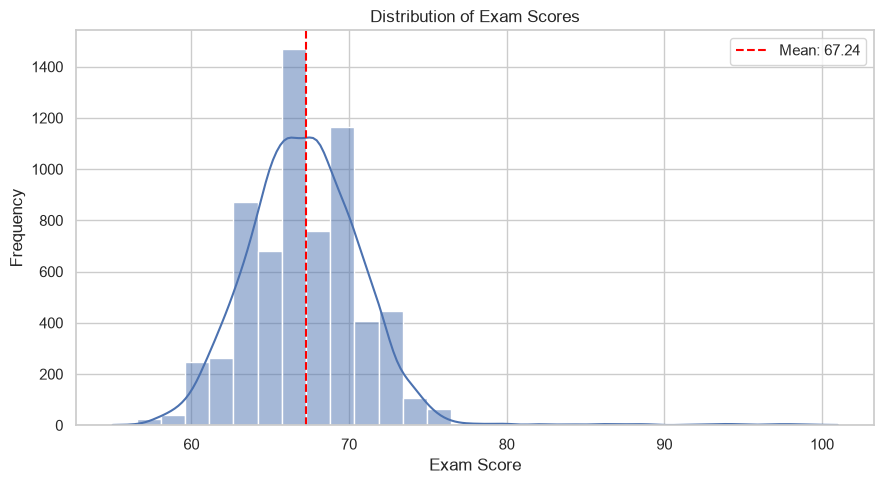

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Exam_Score",
    bins=30,
    kde=True
)

plt.axvline(
    df["Exam_Score"].mean(),
    color="red",
    linestyle="--",
    label=f"Mean: {df['Exam_Score'].mean():.2f}"
)

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()

plt.savefig("figures/01_score_distribution.png", dpi=300)
plt.show()


### 2.2 Correlation Analysis

分析目標：使用 Pearson 相關係數，
檢查數值特徵與考試成績之間的線性關係，
以及各數值特徵彼此的相關性。

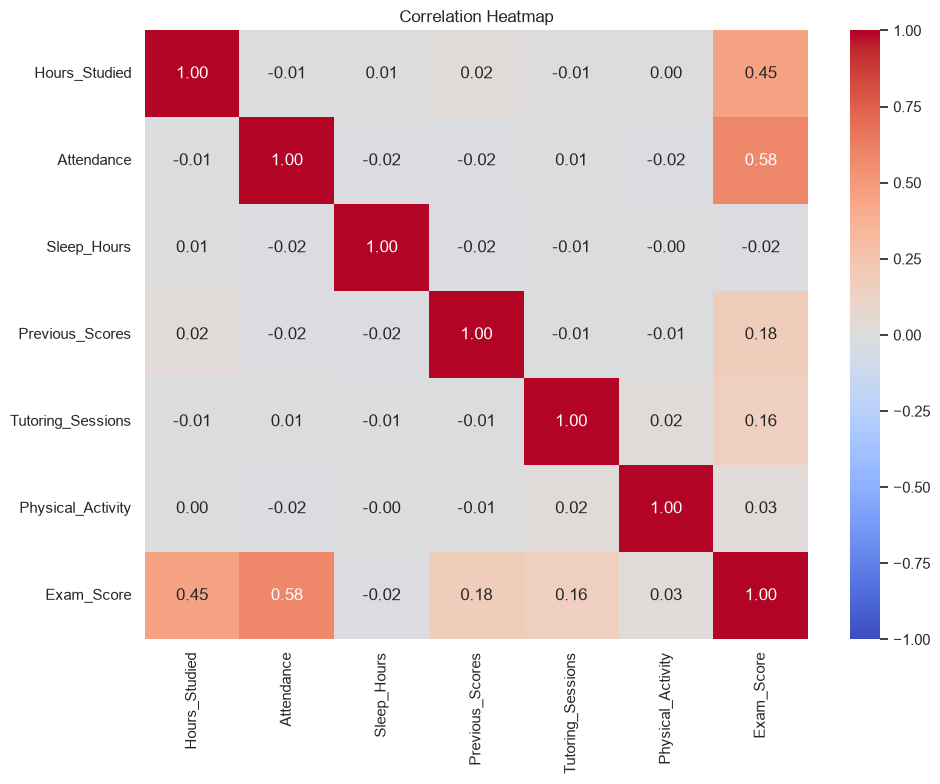

In [10]:
numeric_df = df.select_dtypes(include="number")

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.savefig("figures/02_correlation_heatmap.png", dpi=300)
plt.show()

In [11]:
score_corr = (
    correlation_matrix["Exam_Score"]
    .drop("Exam_Score")
    .sort_values(ascending=False)
)

display(score_corr.to_frame("Correlation with Exam_Score"))

,Correlation with Exam_Score
Attendance,0.581072
Hours_Studied,0.445455
Previous_Scores,0.175079
Tutoring_Sessions,0.156525
Physical_Activity,0.027824
Sleep_Hours,-0.017022


### 2.3 Hours Studied vs. Exam Score

分析目標：探索每週讀書時間與考試成績之間的關係，
觀察是否存在適合線性回歸描述的趨勢。

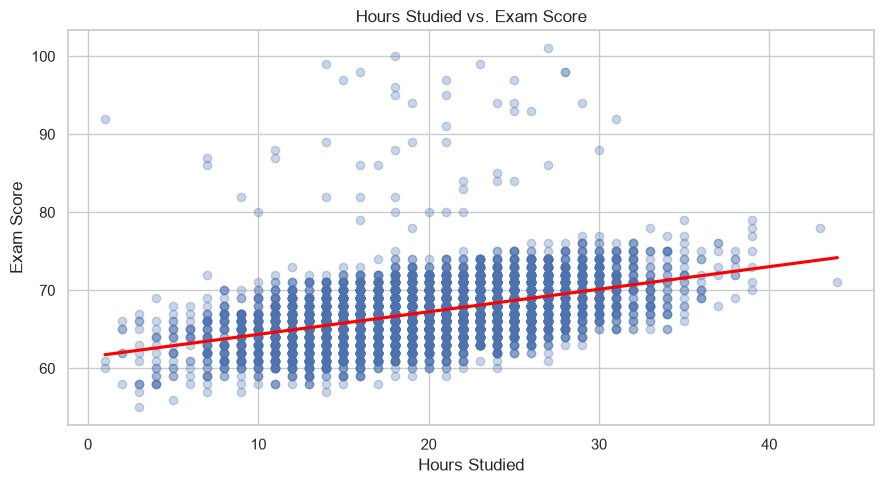

In [12]:
plt.figure(figsize=(9, 5))

sns.regplot(
    data=df,
    x="Hours_Studied",
    y="Exam_Score",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"},
    ci=None
)

plt.title("Hours Studied vs. Exam Score")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.tight_layout()

plt.savefig("figures/03_study_hours_vs_score.png", dpi=300)
plt.show()

### 2.4 Preliminary Findings

本研究透過探索式資料分析（EDA），檢視 Student Performance Factors 資料集的分布特性、數值變數之間的相關性，以及學習時間與考試成績的關係。

**考試成績分布：**  
根據 Fig. 1 
- 平均成績為 67.24 分，由紅色虛線標示。
- 大部分學生成績集中在約 60～75 分。
- 分布主體接近鐘形，但右側有少數高分紀錄，呈現右尾較長的現象。
- 少部分成績高於 90 分，甚至有接近或超過 100 分的紀錄。
整體而言，學生成績主要集中在中間區間，但存在少數明顯偏離主要分布的高分紀錄。

**特徵相關性：**  
根據 Fig. 2 
第一，出席率比讀書時間具有更高的線性相關性。
Attendance 的相關係數為 0.58，而 Hours_Studied 為 0.45。
這表示在目前資料中，出席率與成績具有較強的正向線性關聯，但不代表出席率一定具有更大的因果影響。
第二，過去成績及補習次數也具有一定關聯。
Previous_Scores 和 Tutoring_Sessions 的相關係數分別為 0.18、0.16。
雖然不高，但在多元線性回歸中，這些特徵仍可能提供額外資訊。
第三，數值特徵之間沒有明顯的高度線性相關。
從熱力圖可以看到，數值輸入特徵彼此的相關係數大多接近 0。
這表示目前沒有觀察到明顯的成對高度相關問題，對建立多元線性回歸是有利的。
不過，這還不能完全排除多重共線性。後續若要深入檢查，可以再觀察 VIF。

**讀書時間與成績：**  
根據 Fig. 3 
1. 存在明顯的正向線性趨勢
紅色迴歸趨勢線由左下往右上，表示讀書時間越長的學生，平均而言，考試成績也傾向越高。
這與 Heatmap 中 Hours_Studied 和 Exam_Score 的相關係數 +0.45 一致。
2. 單靠讀書時間還無法準確預測所有學生的成績
你可以看到，在相同讀書時間附近，考試成績仍然有差異。
這表示成績可能還受到出席率、過去成績、學習資源等其他因素影響。
因此，這張圖非常適合作為我們從單純線性回歸進一步發展多元線性回歸的理由。
3. 存在少數特別高的成績紀錄
有部分學生分數落在 80～100 分以上，明顯高於主要的密集區。
這些點可能對模型的殘差、RMSE 和預測區間造成影響，後續 Evaluation 應特別留意。

**下一階段分析方向：**  
由於資料同時包含數值及類別特徵，後續將進行缺失值處理、類別編碼與訓練測試集切分，再建立單純線性回歸、多元線性回歸及 RFE 特徵選擇模型，驗證不同特徵組合的預測效果。

### 2.4 Exploratory Data Analysis Findings

本研究針對 Student Performance Factors 資料集進行探索式資料分析（EDA），以了解學生成績的分布特性，以及各項數值特徵與考試成績之間的關係。

首先，由考試成績分布圖可以觀察到，學生平均考試成績約為 **67.24 分**，大部分成績集中在 60～75 分之間，整體分布接近鐘形，但右側存在少數明顯偏高的成績紀錄，顯示資料可能具有極端值，後續建模時需進一步評估其影響。

其次，Pearson 相關係數分析顯示，**Attendance（出席率）與 Exam_Score 的相關係數為 0.58**，是六個數值輸入特徵中最高者；其次為 **Hours_Studied（讀書時間），相關係數為 0.45**。Previous_Scores 與 Tutoring_Sessions 分別具有 0.18 與 0.16 的弱正相關，而 Sleep_Hours 和 Physical_Activity 與成績的線性相關性較低。

最後，讀書時間與考試成績的散佈圖呈現正向線性趨勢，但相同讀書時間的學生仍存在一定程度的成績差異，顯示單一特徵可能不足以完整預測考試成績。

綜合以上結果，本研究將進一步建立單純線性回歸與多元線性回歸模型，並使用 RFE 特徵選擇方法，比較不同特徵組合的預測表現。需要注意的是，本資料集屬於合成資料，因此上述結果反映的是資料中的統計關聯，而非真實教育情境中的因果關係。

In [ ]:
# 檢查 Exam_Score 的分數範圍
print("最低成績：", df["Exam_Score"].min())
print("最高成績：", df["Exam_Score"].max())

# 統計超過 100 分的紀錄
above_100 = df[df["Exam_Score"] > 100]

print("超過 100 分的筆數：", len(above_100))

display(above_100)

最低成績： 55
最高成績： 101
超過 100 分的筆數： 1


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
1525,27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,101


In [ ]:
# 檢查各欄位缺失值
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Rate (%)": df.isnull().mean() * 100
})

display(missing_summary[missing_summary["Missing Count"] > 0])

,Missing Count,Missing Rate (%)
Teacher_Quality,78,1.180566
Parental_Education_Level,90,1.362192
Distance_from_Home,67,1.014076


## 3. Data Preparation

### 3.1 Data Cleaning

本研究採用 0～100 分的考試成績範圍。
資料集中發現一筆 Exam_Score = 101 的紀錄，
因此將其排除，避免超出研究定義的分數範圍。

其他資料保持不變，缺失值將於後續的
前處理 Pipeline 中處理。

In [ ]:
# 保留 Exam_Score 在 0～100 分之間的資料
df_clean = df[
    df["Exam_Score"].between(0, 100)
].copy()

print("原始資料筆數：", len(df))
print("清理後資料筆數：", len(df_clean))
print("排除資料筆數：", len(df) - len(df_clean))

原始資料筆數： 6607
清理後資料筆數： 6606
排除資料筆數： 1


In [16]:
# 分離輸入特徵與預測目標
X = df_clean.drop(columns=["Exam_Score"])
y = df_clean["Exam_Score"]

print("X 的形狀：", X.shape)
print("y 的形狀：", y.shape)


X 的形狀： (6606, 19)
y 的形狀： (6606,)


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (5284, 19)
X_test: (1322, 19)
y_train: (5284,)
y_test: (1322,)


### 3.1 Data Cleaning and Train-Test Split

本研究原始資料集共有 6,607 筆紀錄及 20 個欄位，其中 19 個為輸入特徵，Exam_Score 為預測目標。

資料品質檢查發現 Teacher_Quality、Parental_Education_Level 及 Distance_from_Home 分別有 78、90 與 67 筆缺失值，缺失比例介於 1.01%～1.36%。由於缺失比例較低且皆為類別特徵，本研究規劃於模型前處理階段使用訓練資料的眾數進行填補。

另外，資料中存在一筆 Exam_Score 為 101 分的紀錄。本研究將考試成績定義為 0～100 分，因此排除此筆超出研究範圍的資料，保留 6,606 筆有效紀錄。

接著將 Exam_Score 設定為目標變數 y，其餘 19 個特徵作為輸入變數 X，並使用 train_test_split，以 80% 作為訓練集、20% 作為測試集，設定 random_state=42 以確保結果可重現。

最終訓練集包含 5,284 筆資料，測試集包含 1,322 筆資料。後續缺失值填補、特徵編碼與特徵選擇皆依訓練資料建立，以降低資料洩漏風險。

### 3.2 Feature Type Identification

本研究將輸入特徵區分為數值型與類別型特徵，
並根據資料型態使用不同的前處理方法。

In [18]:
# 區分數值型與類別型特徵
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("數值特徵：", numeric_features)
print("類別特徵：", categorical_features)

print("\n數值特徵數量：", len(numeric_features))
print("類別特徵數量：", len(categorical_features))

數值特徵： ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
類別特徵： ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

數值特徵數量： 6
類別特徵數量： 13


C:\Users\user\AppData\Local\Temp\ipykernel_49316\763027564.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [19]:
#建立完整前處理器

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 數值特徵前處理
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 類別特徵前處理
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# 合併數值與類別前處理
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("前處理器建立成功！")


前處理器建立成功！


In [20]:
#驗證前處理結果

from sklearn.base import clone

# 使用副本測試前處理器
preprocessor_check = clone(preprocessor)

X_train_processed = preprocessor_check.fit_transform(X_train)

feature_names = preprocessor_check.get_feature_names_out()

print("原始訓練集形狀：", X_train.shape)
print("前處理後形狀：", X_train_processed.shape)
print("前處理後特徵數：", len(feature_names))

display(pd.DataFrame(
    X_train_processed,
    columns=feature_names
).head())


原始訓練集形狀： (5284, 19)
前處理後形狀： (5284, 27)
前處理後特徵數： 27


,num__Hours_Studied,num__Attendance,num__Sleep_Hours,num__Previous_Scores,num__Tutoring_Sessions,num__Physical_Activity,cat__Parental_Involvement_Low,cat__Parental_Involvement_Medium,cat__Access_to_Resources_Low,cat__Access_to_Resources_Medium,...,cat__Teacher_Quality_Medium,cat__School_Type_Public,cat__Peer_Influence_Neutral,cat__Peer_Influence_Positive,cat__Learning_Disabilities_Yes,cat__Parental_Education_Level_High School,cat__Parental_Education_Level_Postgraduate,cat__Distance_from_Home_Moderate,cat__Distance_from_Home_Near,cat__Gender_Male
0,-1.509761,-0.433104,1.345705,0.136860,-0.398416,-0.945182,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
1,-2.012507,-0.606517,0.665320,0.206483,-1.209679,0.025913,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
2,-1.677343,-0.346398,-2.056220,-0.489743,-0.398416,2.939199,0.0,1.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
3,-0.001522,0.347251,-0.015065,-0.072007,-0.398416,0.025913,1.0,0.0,1.0,0.0,...,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
4,-0.001522,-1.560285,-2.056220,1.598934,-0.398416,0.997008,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0


為什麼特徵變27?
因為 One-Hot Encoding 將 13 個類別特徵展開成了 21 個編碼欄位，加上原本的 6 個數值特徵：
6+21=27

### 3.2 Feature Preprocessing

本研究將 19 個原始輸入特徵區分為 6 個數值型特徵及 13 個類別型特徵，並使用 scikit-learn 的 ColumnTransformer 與 Pipeline 建立資料前處理流程。

數值特徵使用 SimpleImputer 的 median 策略處理可能存在的缺失值，再透過 StandardScaler 進行標準化，使不同尺度的數值特徵能以較一致的方式進入模型。

類別特徵則使用 SimpleImputer 的 most_frequent 策略填補缺失值，接著透過 OneHotEncoder 將類別資料轉換為數值欄位，並設定 drop="first" 以移除各類別特徵的一個參考類別。

所有前處理步驟皆將整合於模型 Pipeline 中，並僅使用訓練資料擬合，以避免資料洩漏。由於 One-Hot Encoding 會展開類別欄位，因此前處理後的特徵數可能高於原始的 19 個輸入特徵。

## 4. Modeling

### 4.1 Model A: Simple Linear Regression

本模型僅使用 Hours_Studied 作為輸入特徵，
建立簡單線性回歸模型，作為後續多元線性回歸的比較基準。

In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Model A 只使用 Hours_Studied
X_train_A = X_train[["Hours_Studied"]]
X_test_A = X_test[["Hours_Studied"]]

model_A = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

# 訓練模型
model_A.fit(X_train_A, y_train)

# 預測測試集
y_pred_A = model_A.predict(X_test_A)

print("Model A 訓練完成！")


Model A 訓練完成！


In [22]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_A = mean_absolute_error(y_test, y_pred_A)
rmse_A = np.sqrt(mean_squared_error(y_test, y_pred_A))
r2_A = r2_score(y_test, y_pred_A)

print("=== Model A Evaluation ===")
print(f"MAE:  {mae_A:.4f}")
print(f"RMSE: {rmse_A:.4f}")
print(f"R²:   {r2_A:.4f}")


=== Model A Evaluation ===
MAE:  2.4190
RMSE: 3.1559
R²:   0.2469


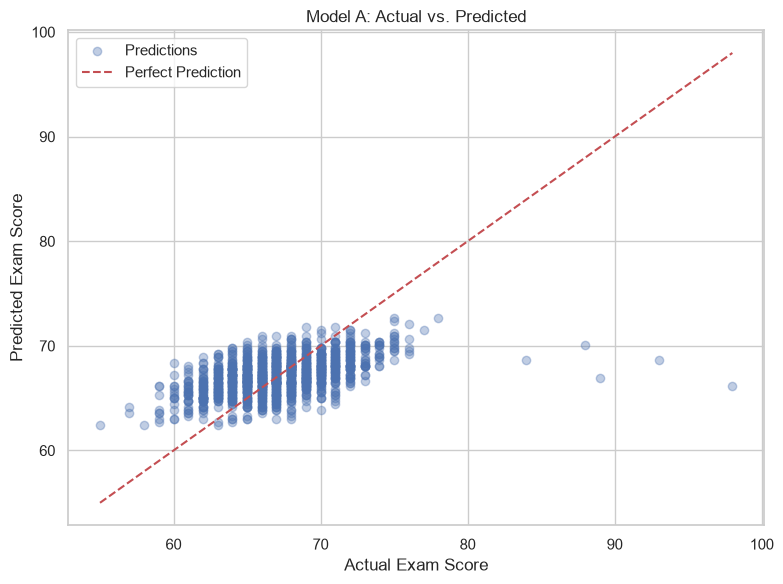

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_A,
    alpha=0.35,
    label="Predictions"
)

min_score = min(y_test.min(), y_pred_A.min())
max_score = max(y_test.max(), y_pred_A.max())

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Model A: Actual vs. Predicted")
plt.legend()
plt.tight_layout()

plt.savefig("figures/04_model_A_predictions.png", dpi=300)
plt.show()


### 4.1 Model A: Simple Linear Regression

本研究首先建立簡單線性回歸模型（Simple Linear Regression），以 Hours_Studied 作為唯一輸入特徵，Exam_Score 作為預測目標，藉此建立後續模型比較的基準。

模型使用 scikit-learn 的 LinearRegression 建立，並透過 Pipeline 結合 StandardScaler，確保數值標準化僅依據訓練資料進行。

訓練集包含 5,284 筆資料，測試集包含 1,322 筆資料。模型訓練完成後，使用 MAE、RMSE 及 R² 評估測試集預測效能，並繪製 Actual vs. Predicted 散佈圖，以觀察模型預測值與真實考試成績之間的差異。

本模型作為 Baseline，後續將加入其他數值及類別特徵建立完整多元線性回歸模型，驗證增加特徵是否能有效改善預測能力。

**模型評估結果：**
- MAE：待實測
- RMSE：待實測
- R²：待實測

### 4.1 Model A：Simple Linear Regression 結果分析

本研究首先使用 Hours_Studied 作為唯一輸入特徵，建立簡單線性回歸模型，並以獨立測試集評估其預測效能。

實驗結果顯示，Model A 的 MAE 為 **2.4190**、RMSE 為 **3.1559**，R² 為 **0.2469**，表示僅使用讀書時間能夠提供一定程度的成績預測能力，但仍有許多成績變異無法被模型解釋。

由 Actual vs. Predicted 散佈圖可觀察到，模型預測值大多集中在約 62～73 分之間。對於部分實際成績較高的學生，模型出現明顯低估的情況；部分低分學生則有被高估的現象。

上述結果顯示，單純使用讀書時間可能不足以準確預測不同學生的考試成績。因此，下一階段將加入出席率、過去成績、家庭背景與學校環境等其他特徵，建立完整多元線性回歸模型，以評估增加特徵是否能改善預測準確度。

### 4.2 Model B: Multiple Linear Regression

本模型使用全部 19 個原始輸入特徵，
經由缺失值填補、標準化及 One-Hot Encoding 後，
建立多元線性回歸模型。

研究目的是比較使用多個特徵，
是否能比 Model A 獲得更好的預測效果。

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LinearRegression

model_B = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("regressor", LinearRegression())
])

# 使用完整訓練集訓練 Model B
model_B.fit(X_train, y_train)

# 預測測試集
y_pred_B = model_B.predict(X_test)

print("Model B 訓練完成！")


Model B 訓練完成！


In [25]:
mae_B = mean_absolute_error(y_test, y_pred_B)
rmse_B = np.sqrt(mean_squared_error(y_test, y_pred_B))
r2_B = r2_score(y_test, y_pred_B)

print("=== Model B Evaluation ===")
print(f"MAE:  {mae_B:.4f}")
print(f"RMSE: {rmse_B:.4f}")
print(f"R²:   {r2_B:.4f}")


=== Model B Evaluation ===
MAE:  0.4160
RMSE: 1.5213
R²:   0.8250


In [26]:
comparison = pd.DataFrame({
    "Model": [
        "Model A: Simple LR",
        "Model B: Multiple LR"
    ],
    "MAE": [mae_A, mae_B],
    "RMSE": [rmse_A, rmse_B],
    "R2": [r2_A, r2_B]
})

display(comparison.round(4))


,Model,MAE,RMSE,R2
0,Model A: Simple LR,2.419,3.1559,0.2469
1,Model B: Multiple LR,0.416,1.5213,0.8250


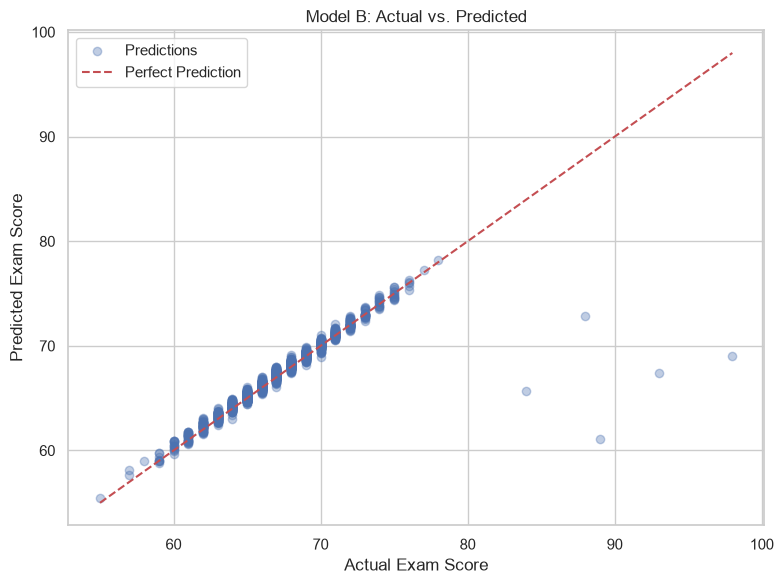

In [27]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_B,
    alpha=0.35,
    label="Predictions"
)

min_score = min(y_test.min(), y_pred_B.min())
max_score = max(y_test.max(), y_pred_B.max())

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Model B: Actual vs. Predicted")
plt.legend()
plt.tight_layout()

plt.savefig("figures/05_model_B_predictions.png", dpi=300)
plt.show()


### 4.2 Model B：Multiple Linear Regression 結果分析

本研究使用全部 19 個原始輸入特徵，經過缺失值填補、標準化及 One-Hot Encoding 後，建立多元線性回歸模型。模型使用 5,284 筆訓練資料訓練，並以 1,322 筆獨立測試資料進行評估。

實驗結果顯示，Model B 的 MAE 為 **0.4160**、RMSE 為 **1.5213**，R² 為 **0.8250**。相較於僅使用 Hours_Studied 的 Model A，MAE 降低約 82.8%，RMSE 降低約 51.8%，R² 則由 0.2469 提升至 0.8250。

由 Actual vs. Predicted 散佈圖可以觀察到，大部分預測結果接近理想預測線，表示整體預測表現良好。然而，部分實際成績較高的學生仍存在明顯低估現象，顯示模型對少數極端高分紀錄的預測能力有限。

綜合而言，研究結果支持增加多個特徵有助於改善考試成績預測的假設。下一階段將使用 Recursive Feature Elimination（RFE）進行特徵選擇，探討是否能在減少模型特徵數量的情況下，維持接近完整模型的預測效能。

### 4.3 Model C: Multiple Linear Regression with RFE

本研究使用 Recursive Feature Elimination (RFE)
執行特徵選擇，並搭配 5-Fold Cross-Validation，
比較不同特徵數量的模型表現。

特徵選擇與交叉驗證僅使用訓練資料，
以避免測試資料洩漏。

In [28]:
from sklearn.feature_selection import RFE
from sklearn.model_selection import GridSearchCV, KFold

# 建立包含前處理、RFE、線性回歸的 Pipeline
model_C_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("selector", RFE(estimator=LinearRegression())),
    ("regressor", LinearRegression())
])

# 測試不同的編碼後特徵數量
param_grid = {
    "selector__n_features_to_select": [5, 10, 15, 20, 25, 27]
}

# 五折交叉驗證
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 使用 RMSE 選擇特徵數量
model_C_search = GridSearchCV(
    estimator=model_C_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

# 只使用訓練集進行特徵選擇
model_C_search.fit(X_train, y_train)

print("最佳特徵數：", model_C_search.best_params_)
print("最佳交叉驗證 RMSE：", -model_C_search.best_score_)


最佳特徵數： {'selector__n_features_to_select': 25}
最佳交叉驗證 RMSE： 2.083319073717079


In [29]:
cv_results = pd.DataFrame({
    "Feature Count": model_C_search.cv_results_[
        "param_selector__n_features_to_select"
    ].astype(int),
    "CV RMSE": -model_C_search.cv_results_[
        "mean_test_score"
    ]
}).sort_values("Feature Count")

display(cv_results.round(4))


,Feature Count,CV RMSE
0,5,2.5165
1,10,2.4230
2,15,2.2135
3,20,2.1175
4,25,2.0833
5,27,2.0840


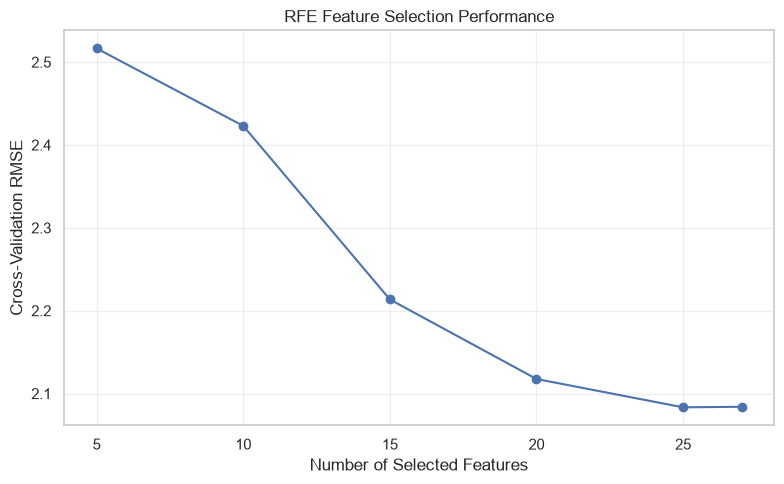

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    cv_results["Feature Count"],
    cv_results["CV RMSE"],
    marker="o"
)

plt.xlabel("Number of Selected Features")
plt.ylabel("Cross-Validation RMSE")
plt.title("RFE Feature Selection Performance")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("figures/06_rfe_cv_results.png", dpi=300)
plt.show()


In [31]:
# 取得交叉驗證選出的最佳模型
model_C = model_C_search.best_estimator_

# 取得經過前處理的特徵名稱
feature_names_C = model_C.named_steps[
    "preprocessor"
].get_feature_names_out()

# 取得 RFE 的特徵選擇結果
selected_mask = model_C.named_steps[
    "selector"
].support_

selected_features = feature_names_C[selected_mask]

print("RFE 選中的編碼後特徵：")
for feature in selected_features:
    print(feature)

print("\n選中數量：", len(selected_features))


RFE 選中的編碼後特徵：
num__Hours_Studied
num__Attendance
num__Previous_Scores
num__Tutoring_Sessions
num__Physical_Activity
cat__Parental_Involvement_Low
cat__Parental_Involvement_Medium
cat__Access_to_Resources_Low
cat__Access_to_Resources_Medium
cat__Extracurricular_Activities_Yes
cat__Motivation_Level_Low
cat__Motivation_Level_Medium
cat__Internet_Access_Yes
cat__Family_Income_Low
cat__Family_Income_Medium
cat__Teacher_Quality_Low
cat__Teacher_Quality_Medium
cat__Peer_Influence_Neutral
cat__Peer_Influence_Positive
cat__Learning_Disabilities_Yes
cat__Parental_Education_Level_High School
cat__Parental_Education_Level_Postgraduate
cat__Distance_from_Home_Moderate
cat__Distance_from_Home_Near
cat__Gender_Male

選中數量： 25


### 4.3 Model C：RFE Feature Selection

本研究使用 Recursive Feature Elimination（RFE）執行特徵選擇，並搭配 5-Fold Cross-Validation 比較不同特徵數量的模型表現。實驗設定保留 5、10、15、20、25 與 27 個編碼後特徵，並以交叉驗證 RMSE 作為選擇標準。

實驗結果顯示，當特徵數量由 5 增加至 25 時，交叉驗證 RMSE 由 2.5165 逐漸下降至 **2.0833**。當使用全部 27 個特徵時，RMSE 為 2.0840，與使用 25 個特徵的結果非常接近。

因此，本研究在預先設定的候選範圍中選擇保留 25 個編碼後特徵，較完整模型減少約 7.4% 的特徵數量。

RFE 最終移除了 Sleep_Hours 與 School_Type_Public 兩個欄位。其中 Sleep_Hours 與先前探索式資料分析中呈現的低線性相關性一致。不過，特徵選擇結果反映的是目前資料與模型設定下的預測貢獻，不能直接作為因果關係的證據。

後續將使用獨立測試集，進一步比較完整模型與 RFE 模型的預測準確度，驗證特徵選擇是否在維持效能的同時降低模型複雜度。

## 5. Evaluation

### 5.1 Model C Evaluation

使用獨立測試集評估經 RFE 特徵選擇後的
多元線性回歸模型，並與 Model A、Model B 比較。

Model C 透過 5-Fold Cross-Validation 選擇特徵數，
最終保留 25 個編碼後特徵。


In [32]:
# Model C 已由 GridSearchCV 完成訓練
model_C = model_C_search.best_estimator_

# 使用測試資料進行預測
y_pred_C = model_C.predict(X_test)

# 計算評估指標
mae_C = mean_absolute_error(y_test, y_pred_C)
rmse_C = np.sqrt(mean_squared_error(y_test, y_pred_C))
r2_C = r2_score(y_test, y_pred_C)

print("=== Model C Evaluation ===")
print(f"MAE:  {mae_C:.4f}")
print(f"RMSE: {rmse_C:.4f}")
print(f"R²:   {r2_C:.4f}")


=== Model C Evaluation ===
MAE:  0.4157
RMSE: 1.5210
R²:   0.8251


In [35]:
#建立三個模型的比較表
comparison = pd.DataFrame({
    "Model": [
        "Model A: Simple LR",
        "Model B: Multiple LR",
        "Model C: Multiple LR + RFE"
    ],
    "Features": [1, 27, 25],
    "MAE": [mae_A, mae_B, mae_C],
    "RMSE": [rmse_A, rmse_B, rmse_C],
    "R2": [r2_A, r2_B, r2_C]
})

display(comparison.round(4))


,Model,Features,MAE,RMSE,R2
0,Model A: Simple LR,1,2.4190,3.1559,0.2469
1,Model B: Multiple LR,27,0.4160,1.5213,0.8250
2,Model C: Multiple LR + RFE,25,0.4157,1.5210,0.8251


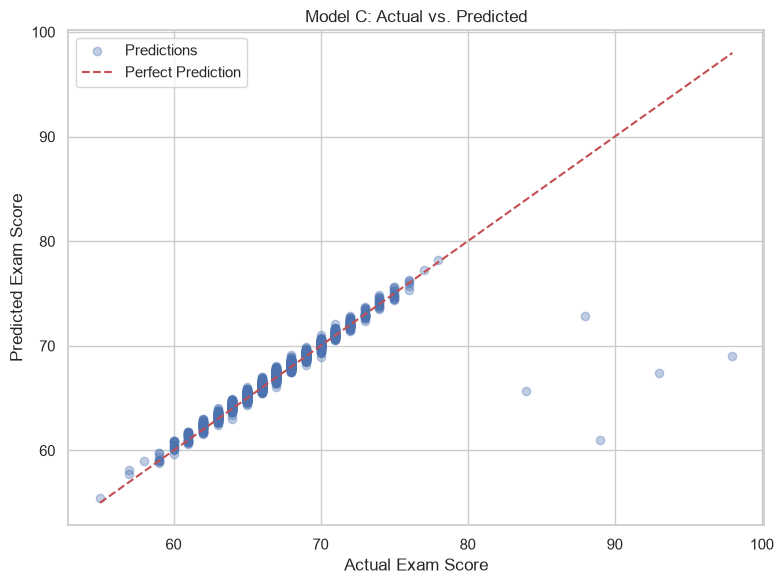

In [36]:
#繪製 Model C 預測圖
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_C,
    alpha=0.35,
    label="Predictions"
)

min_score = min(y_test.min(), y_pred_C.min())
max_score = max(y_test.max(), y_pred_C.max())

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Model C: Actual vs. Predicted")
plt.legend()
plt.tight_layout()

plt.savefig("figures/07_model_C_predictions.png", dpi=300)
plt.show()


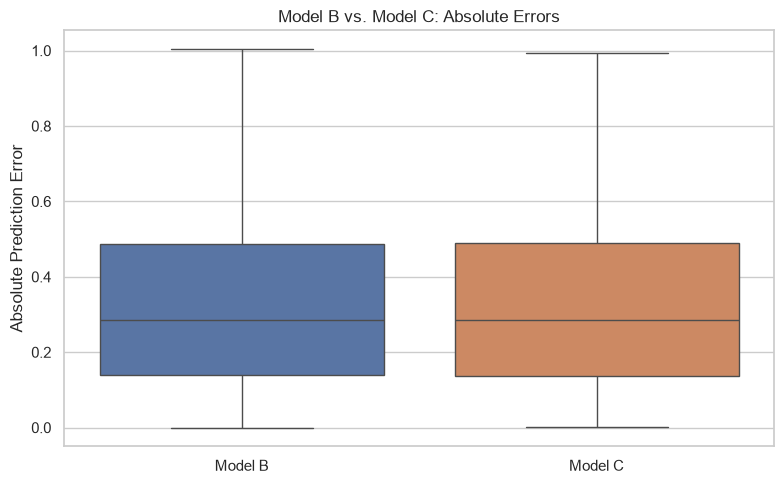

In [38]:
#比較 Model B 與 Model C 的預測誤差
absolute_error_B = np.abs(y_test.to_numpy() - y_pred_B)
absolute_error_C = np.abs(y_test.to_numpy() - y_pred_C)

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=pd.DataFrame({
        "Model B": absolute_error_B,
        "Model C": absolute_error_C
    }),
    showfliers=False
)

plt.ylabel("Absolute Prediction Error")
plt.title("Model B vs. Model C: Absolute Errors")
plt.tight_layout()

plt.savefig("figures/08_model_B_C_errors.png", dpi=300)
plt.show()


### 5.2 Residual Analysis

本研究使用殘差分析檢查 Model C 的預測誤差，
觀察誤差是否存在系統性偏差及極端值。

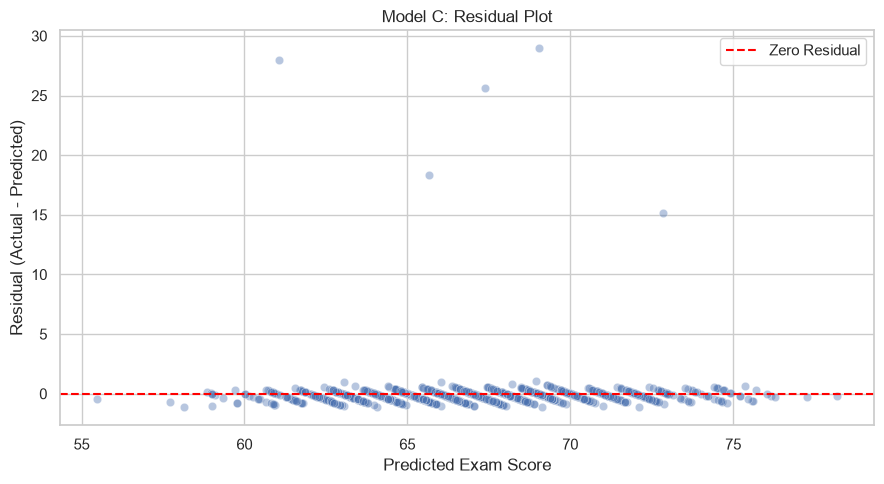

In [39]:
# 計算 Model C 殘差
residuals_C = y_test.to_numpy() - y_pred_C

plt.figure(figsize=(9, 5))

sns.scatterplot(
    x=y_pred_C,
    y=residuals_C,
    alpha=0.4
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Residual"
)

plt.xlabel("Predicted Exam Score")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Model C: Residual Plot")
plt.legend()
plt.tight_layout()

plt.savefig("figures/09_model_C_residuals.png", dpi=300)
plt.show()


In [40]:
error_analysis = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred_C,
    "Residual": residuals_C,
    "Absolute Error": np.abs(residuals_C)
}, index=y_test.index)

display(
    error_analysis
    .sort_values("Absolute Error", ascending=False)
    .head(10)
)


,Actual,Predicted,Residual,Absolute Error
6393,98,69.048925,28.951075,28.951075
217,89,61.048905,27.951095,27.951095
4583,93,67.371144,25.628856,25.628856
3932,84,65.657890,18.342110,18.342110
1607,88,72.832022,15.167978,15.167978
2880,57,58.141743,-1.141743,1.141743
5160,68,69.123706,-1.123706,1.123706
1393,71,72.101315,-1.101315,1.101315
5020,63,64.078624,-1.078624,1.078624
4875,70,68.945571,1.054429,1.054429


### 5.3 95% Prediction Interval

使用 Split Conformal Prediction 建立 95% 預測區間。

將原本的訓練資料分成模型擬合集與校準集，
在擬合集內重新執行交叉驗證及特徵選擇，
再使用獨立校準集估計預測誤差分位數。

最後使用原本的測試集評估區間涵蓋率。

In [41]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone

# 從原本的訓練集切出校準集
X_fit, X_cal, y_fit, y_cal = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

# 在擬合集內重新執行 Model C 的特徵選擇
interval_search = clone(model_C_search)
interval_search.fit(X_fit, y_fit)

interval_model = interval_search.best_estimator_

# 計算校準集的絕對預測誤差
cal_pred = interval_model.predict(X_cal)
cal_errors = np.abs(y_cal.to_numpy() - cal_pred)

# Split Conformal 的 95% 誤差分位數
n_cal = len(cal_errors)
quantile_level = np.ceil((n_cal + 1) * 0.95) / n_cal

q = np.quantile(
    cal_errors,
    quantile_level,
    method="higher"
)

print("校準集筆數：", n_cal)
print("校準誤差分位數：", round(q, 4))


校準集筆數： 1057
校準誤差分位數： 0.8044


In [ ]:
# step20-3 計算預測區間與涵蓋率
# 使用區間模型預測測試集
interval_pred = interval_model.predict(X_test)

# 計算上下界
lower_bound = interval_pred - q
upper_bound = interval_pred + q

# 計算測試集涵蓋率
actual = y_test.to_numpy()

covered = (
    (actual >= lower_bound) &
    (actual <= upper_bound)
)

coverage = covered.mean()
average_width = np.mean(upper_bound - lower_bound)

print(f"95% Prediction Interval Coverage: {coverage:.2%}")
print(f"Average Interval Width: {average_width:.4f}")


95% Prediction Interval Coverage: 95.08%
Average Interval Width: 1.6089


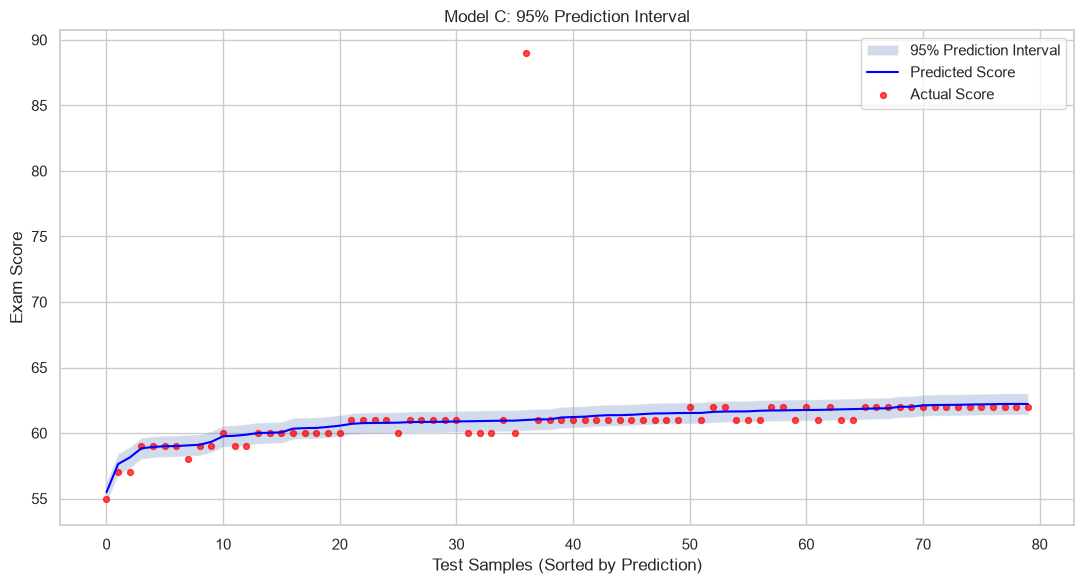

In [43]:
#Step 20-4：繪製 95% 預測區間圖

# 將測試結果整理成表格
interval_results = pd.DataFrame({
    "Actual": actual,
    "Predicted": interval_pred,
    "Lower": lower_bound,
    "Upper": upper_bound
})

# 依預測值排序，取前 80 筆作圖
plot_data = (
    interval_results
    .sort_values("Predicted")
    .head(80)
    .reset_index(drop=True)
)

x = np.arange(len(plot_data))

plt.figure(figsize=(11, 6))

plt.fill_between(
    x,
    plot_data["Lower"],
    plot_data["Upper"],
    alpha=0.25,
    label="95% Prediction Interval"
)

plt.plot(
    x,
    plot_data["Predicted"],
    color="blue",
    label="Predicted Score"
)

plt.scatter(
    x,
    plot_data["Actual"],
    color="red",
    s=18,
    alpha=0.7,
    label="Actual Score"
)

plt.xlabel("Test Samples (Sorted by Prediction)")
plt.ylabel("Exam Score")
plt.title("Model C: 95% Prediction Interval")
plt.legend()
plt.tight_layout()

plt.savefig(
    "figures/10_prediction_interval.png",
    dpi=300
)

plt.show()


### 5.2 Residual Analysis and Prediction Interval

本研究針對經 RFE 特徵選擇後的 Model C 進行殘差分析，並使用 Split Conformal Prediction 建立 95% 預測區間，以評估模型的預測誤差與不確定性。

殘差分析結果顯示，大部分測試資料的殘差集中在 0 附近，通常介於 -1 至 +1 分之間，表示模型對主要成績區間具有良好的預測能力。然而，部分高分學生存在明顯的低估情況，其中五筆資料的正殘差約介於 15.17～28.95 分之間。這些極端預測誤差對整體 RMSE 產生了顯著影響，顯示模型在少數高分紀錄上的預測能力仍有限。

在預測區間方面，本研究使用 1,057 筆校準資料，取得校準誤差分位數約 0.8044，建立 95% Split Conformal Prediction Interval。

實驗結果顯示，測試集的實際涵蓋率（Coverage）為 **95.08%**，平均預測區間寬度（Average Interval Width）為 **1.6089 分**。整體而言，預測區間達到接近 95% 的邊際涵蓋率，且對大部分學生提供較窄的預測範圍。

然而，部分極端高分紀錄仍明顯超出預測區間，表示此方法雖具有良好的整體涵蓋率，卻不能保證每個成績區間皆有相同的預測可靠性。

綜合而言，Model C 能以較少特徵維持良好的整體預測能力，但對極端高分學生仍存在明顯限制。由於研究資料屬於合成資料，模型表現與特徵重要性結論不宜直接推廣至真實教育環境。

In [44]:
from pathlib import Path
import joblib

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

# 儲存最終 RFE 模型
joblib.dump(model_C, model_dir / "model_C.joblib")

# 儲存預測區間模型與校準分位數
joblib.dump(
    {
        "model": interval_model,
        "q": q
    },
    model_dir / "prediction_interval.joblib"
)

print("模型儲存完成！")


模型儲存完成！


In [45]:
loaded_model = joblib.load("models/model_C.joblib")

interval_package = joblib.load(
    "models/prediction_interval.joblib"
)

loaded_interval_model = interval_package["model"]
loaded_q = interval_package["q"]

print("模型載入成功！")


模型載入成功！


In [46]:
#示範預測一名學生的成績

# 取得一筆學生資料
student = X_test.iloc[[0]]

# 使用完整訓練集模型進行點預測
predicted_score = loaded_model.predict(student)[0]

# 使用校準模型產生預測區間
interval_score = loaded_interval_model.predict(student)[0]

lower = interval_score - loaded_q
upper = interval_score + loaded_q

print(f"Model C 預測成績：{predicted_score:.2f}")
print(f"區間模型預測成績：{interval_score:.2f}")
print(f"95% 預測區間：[{lower:.2f}, {upper:.2f}]")
print(f"實際成績：{y_test.iloc[0]}")


Model C 預測成績：66.01
區間模型預測成績：66.06
95% 預測區間：[65.25, 66.86]
實際成績：66


### 6. Deployment

本研究使用 joblib 儲存完成訓練的多元線性回歸與 RFE 特徵選擇模型。儲存內容包含資料前處理、特徵選擇及線性回歸預測流程，使模型重新載入後仍能執行一致的資料轉換與成績預測。

另外，本研究保存獨立的 Split Conformal Prediction 模型及其校準誤差分位數，用於產生 95% 預測區間。

部署測試透過重新載入模型，輸入單筆學生資料並輸出預測成績與預測區間，驗證模型具有基本的可重現性及使用能力。

由於本研究使用合成學生資料，模型目前僅適合教學與方法驗證，不建議直接使用於真實學生的成績評定、升學決策或其他高風險教育用途。

## 8. 網路主流方法與本研究比較

根據 NotebookLM 整理的相關文獻，學生成績預測常使用 Random Forest、XGBoost 及 LightGBM 等集成學習方法。這些模型能夠捕捉非線性關係與特徵之間的交互作用，適用於較複雜的預測問題，但通常需要額外的模型解釋技術。

本研究則採用 Multiple Linear Regression，並透過 RFE 進行特徵選擇。實驗結果顯示，完整多元線性回歸的測試集 R² 為 0.8250，使用 RFE 後為 0.8251，兩者的預測能力幾乎相同。這表示本研究能在減少部分特徵的情況下，維持相近的模型效能。

雖然本研究模型的測試指標數值優於參考文獻所報告的樹狀集成模型，但由於資料切分、前處理及實驗設定不同，不能據此認定多元線性回歸普遍優於 LightGBM 或其他非線性模型。

本研究的主要優勢在於模型結構相對簡單、預測流程容易重現，以及可以透過特徵選擇分析輸入變數的預測貢獻。然而，殘差分析也顯示，模型對少數極端高分學生仍存在顯著低估情況，表示線性模型仍具有一定限制。

綜合而言，不同預測方法各有優缺點。對於目前的合成資料集，多元線性回歸已能提供良好的預測結果；若應用於真實教育資料，仍應在相同資料切分與評估條件下，進一步比較線性模型與非線性模型的泛化能力。